In [1]:
# In this program we will build the project so that we can analyse the potato leaves is infected by which type of diseases either it is early_light or late_light disease 

In [2]:
import tensorflow as tf 
from tensorflow.keras import models, layers
import matplotlib.pyplot as plt 
from IPython.display import HTML 


In [3]:
BATCH_SIZE = 32 
IMAGE_SIZE = 256
CHANNELS = 3 
EPOCHS = 50 

In [4]:
# import data into tensorflow dataset object. here, we will use image_dataset_from_directory api to load all images in tensorflow dataset: 

dataset = tf.keras.preprocessing.image_dataset_from_directory(
    "../PlantVillage_DS",
    seed = 123, # seed -> 
    shuffle=False, 
    image_size = (IMAGE_SIZE, IMAGE_SIZE), 
    batch_size = BATCH_SIZE
)

Found 2152 files belonging to 3 classes.


In [5]:
class_names = dataset.class_names 
print(class_names)

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


In [6]:
print(dataset)

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


In [7]:
# print(len(dataset))
print(dataset)

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


In [8]:
for image_batch, label_batch in dataset.take(1): 
    print(image_batch.shape)
    print(image_batch[0]) # it will print the individual image from 0th index
    # print(image_batch[0].numpy()) # it will convert the tensor into array   
    print(label_batch.numpy())

(32, 256, 256, 3)
tf.Tensor(
[[[123. 120. 127.]
  [161. 158. 165.]
  [147. 144. 151.]
  ...
  [173. 170. 177.]
  [170. 167. 174.]
  [168. 165. 172.]]

 [[131. 128. 135.]
  [147. 144. 151.]
  [141. 138. 145.]
  ...
  [184. 181. 188.]
  [179. 176. 183.]
  [176. 173. 180.]]

 [[149. 146. 153.]
  [134. 131. 138.]
  [132. 129. 136.]
  ...
  [178. 175. 182.]
  [174. 171. 178.]
  [172. 169. 176.]]

 ...

 [[149. 146. 157.]
  [116. 113. 124.]
  [130. 127. 138.]
  ...
  [159. 159. 169.]
  [160. 160. 170.]
  [160. 160. 170.]]

 [[108. 105. 116.]
  [104. 101. 112.]
  [125. 122. 133.]
  ...
  [160. 160. 170.]
  [162. 162. 174.]
  [162. 162. 174.]]

 [[146. 143. 154.]
  [ 92.  89. 100.]
  [127. 124. 135.]
  ...
  [167. 167. 177.]
  [170. 170. 182.]
  [171. 171. 183.]]], shape=(256, 256, 3), dtype=float32)
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


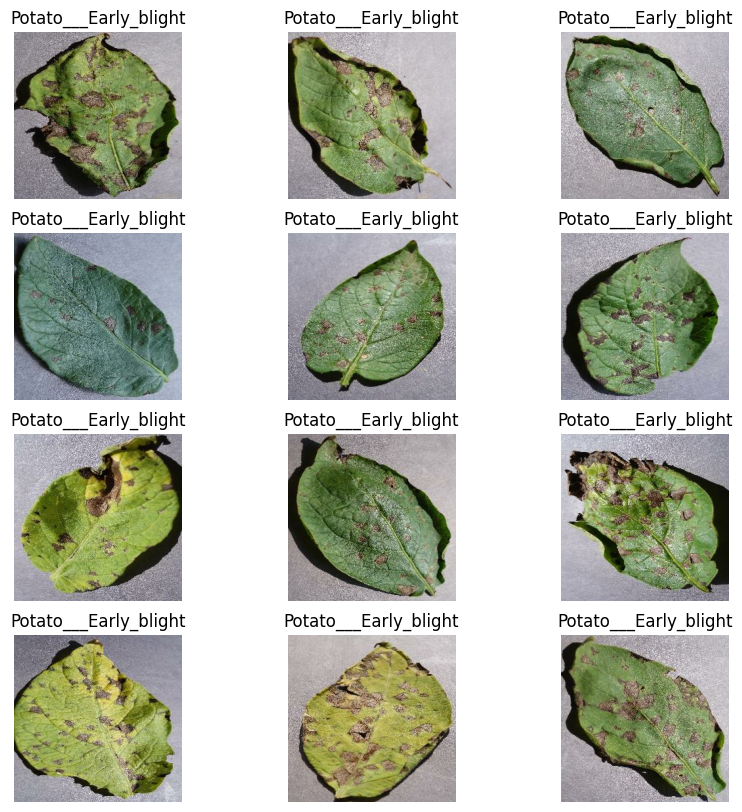

In [9]:
plt.figure(figsize=(10,10))
for image_batch, label_batch in dataset.take(1): # 
    # for i in range(len(label_batch)-1, -1, -1): # 12 is 
    for i in range(12): 
        ax = plt.subplot(4,3, i+1)
        plt.imshow(image_batch[i].numpy().astype("uint8"))
        plt.title(class_names[label_batch[i]])
        plt.axis("off")

In [10]:
# now we will split the dataset into training and testing phase 

print(len(dataset))

# 80% - training 
# 20% - 10% validation, 10% test 

train_size = 0.8 # define 80% training dataset
train_value = int(len(dataset)*train_size)
print(train_value)

68
54


In [11]:
train_ds = dataset.take(train_value)
print(len(train_ds))

54


In [12]:
test_ds = dataset.skip(train_value)
print(len(test_ds))

14


In [13]:
val_size = 0.1
len(dataset)*val_size

6.800000000000001

In [14]:
val_ds = test_ds.take(6)
print(len(val_ds))

6


In [15]:
test_ds = test_ds.skip(6)
len(test_ds)

8

In [16]:
def get_dataset_partitions_tf(ds, train_split=0.8, val_split=0.1, test_split=0.1, shuffle=True, shuffle_size=10000):
    assert (train_split + test_split + val_split) == 1
    
    ds_size = len(ds)
    
    if shuffle:
        ds = ds.shuffle(shuffle_size, seed=12)
    
    train_size = int(train_split * ds_size)
    # print(train_size)
    val_size = int(val_split * ds_size)
    # print(val_size)
    
    train_ds = ds.take(train_size)    
    # print(len(train_ds))
    val_ds = ds.skip(train_size).take(val_size)
    # print(len(val_ds))
    test_ds = ds.skip(train_size).skip(val_size)
    # print(len(test_ds))
    
    return train_ds, val_ds, test_ds

In [17]:
train_ds, val_ds, test_ds = get_dataset_partitions_tf(dataset)
print(train_ds)
print(val_ds)
print(test_ds)

<_TakeDataset element_spec=(TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
<_TakeDataset element_spec=(TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
<_SkipDataset element_spec=(TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


In [18]:
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
print(train_ds)

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


In [19]:
# resize_and_rescale = tf.keras.Sequential([
#   layers.experimental.preprocessing.Resizing(IMAGE_SIZE, IMAGE_SIZE),
#   layers.experimental.preprocessing.Rescaling(1./255),
# ])
resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE), # (256,256)
    layers.Rescaling(1./255),
])

In [20]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
])

In [21]:
train_ds = train_ds.map(
    lambda x, y: (data_augmentation(x, training=True), y)
).prefetch(buffer_size=tf.data.AUTOTUNE)

In [22]:
input_shape = (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
n_classes = 3

model = models.Sequential([
    resize_and_rescale,
    layers.Conv2D(32, kernel_size = (3,3), activation='relu', input_shape=input_shape),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,  kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,  kernel_size = (3,3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(n_classes, activation='softmax'),
])

model.build(input_shape=input_shape)

C:\Users\Admin\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [23]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

In [24]:
history = model.fit(
    train_ds,
    batch_size=BATCH_SIZE,
    validation_data=val_ds,
    verbose=1,
    epochs=50,
)

Epoch 1/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 191s 3s/step - accuracy: 0.2720 - loss: 1.0224 - val_accuracy: 0.5000 - val_loss: 0.8569
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 163s 3s/step - accuracy: 0.4682 - loss: 0.9763 - val_accuracy: 0.5000 - val_loss: 0.8107
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 176s 3s/step - accuracy: 0.4311 - loss: 0.9560 - val_accuracy: 0.5000 - val_loss: 0.7990
Epoch 4/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 179s 3s/step - accuracy: 0.5677 - loss: 1.0303 - val_accuracy: 0.5000 - val_loss: 0.8178
Epoch 5/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 183s 3s/step - accuracy: 0.4578 - loss: 0.9878 - val_accuracy: 0.5000 - val_loss: 0.8892
Epoch 6/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 118s 2s/step - accuracy: 0.4890 - loss: 0.9329 - val_accuracy: 0.4844 - val_loss: 0.7819
Epoch 7/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 135s 2s/step - accuracy: 0.4641 - loss: 0.8908 - val_accuracy: 0.5469 - val_loss: 0.7519
Epoch 8/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 140s 3s/step - accuracy: 0.5272 - loss: 0.8435 - val_accuracy: 0.6302 - v

In [25]:
scores = model.evaluate(test_ds)

8/8 ━━━━━━━━━━━━━━━━━━━━ 8s 496ms/step - accuracy: 0.9023 - loss: 0.2476


In [26]:
scores

[0.2476423978805542, 0.90234375]

In [27]:
history

In [28]:
history.params

{'verbose': 1, 'epochs': 50, 'steps': 54}

In [29]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [30]:
type(history.history['loss'])

list

In [31]:
len(history.history['loss'])

50

In [32]:
history.history['loss'][:5] # show loss for first 5 epochs

[1.0223580598831177,
 0.9762881398200989,
 0.9559697508811951,
 1.0302958488464355,
 0.9877663850784302]

In [33]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

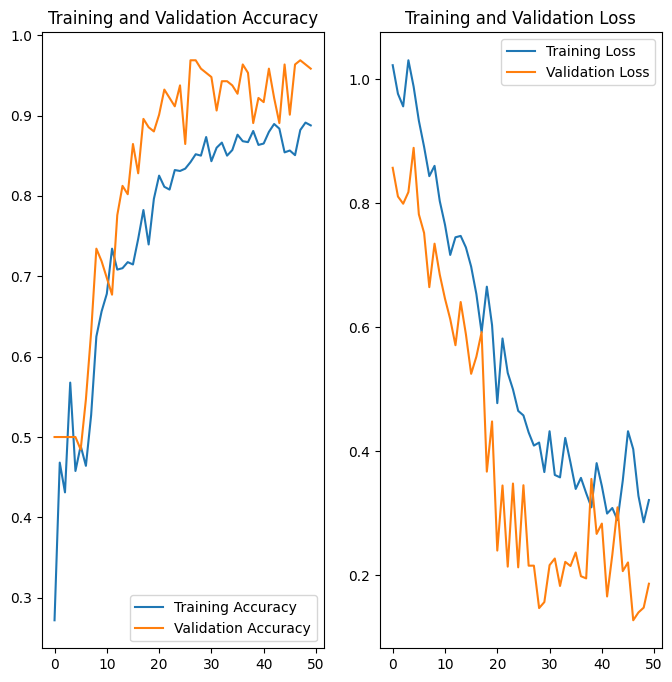

In [34]:
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(range(EPOCHS), acc, label='Training Accuracy')
plt.plot(range(EPOCHS), val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(range(EPOCHS), loss, label='Training Loss')
plt.plot(range(EPOCHS), val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

first image to predict
actual label: Potato___Late_blight
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
predicted label: Potato___Late_blight


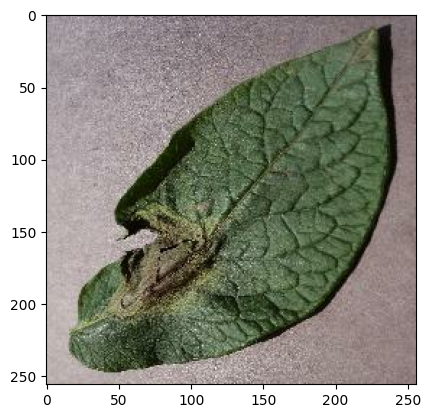

In [35]:
import numpy as np
for images_batch, labels_batch in test_ds.take(1):
    
    first_image = images_batch[0].numpy().astype('uint8')
    first_label = labels_batch[0].numpy()
    
    print("first image to predict")
    plt.imshow(first_image)
    print("actual label:",class_names[first_label])
    
    batch_prediction = model.predict(images_batch)
    print("predicted label:",class_names[np.argmax(batch_prediction[0])])

In [36]:
def predict(model, img):
    img_array = tf.keras.preprocessing.image.img_to_array(images[i].numpy())
    img_array = tf.expand_dims(img_array, 0)

    predictions = model.predict(img_array)

    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(100 * (np.max(predictions[0])), 2)
    return predicted_class, confidence

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 183ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step


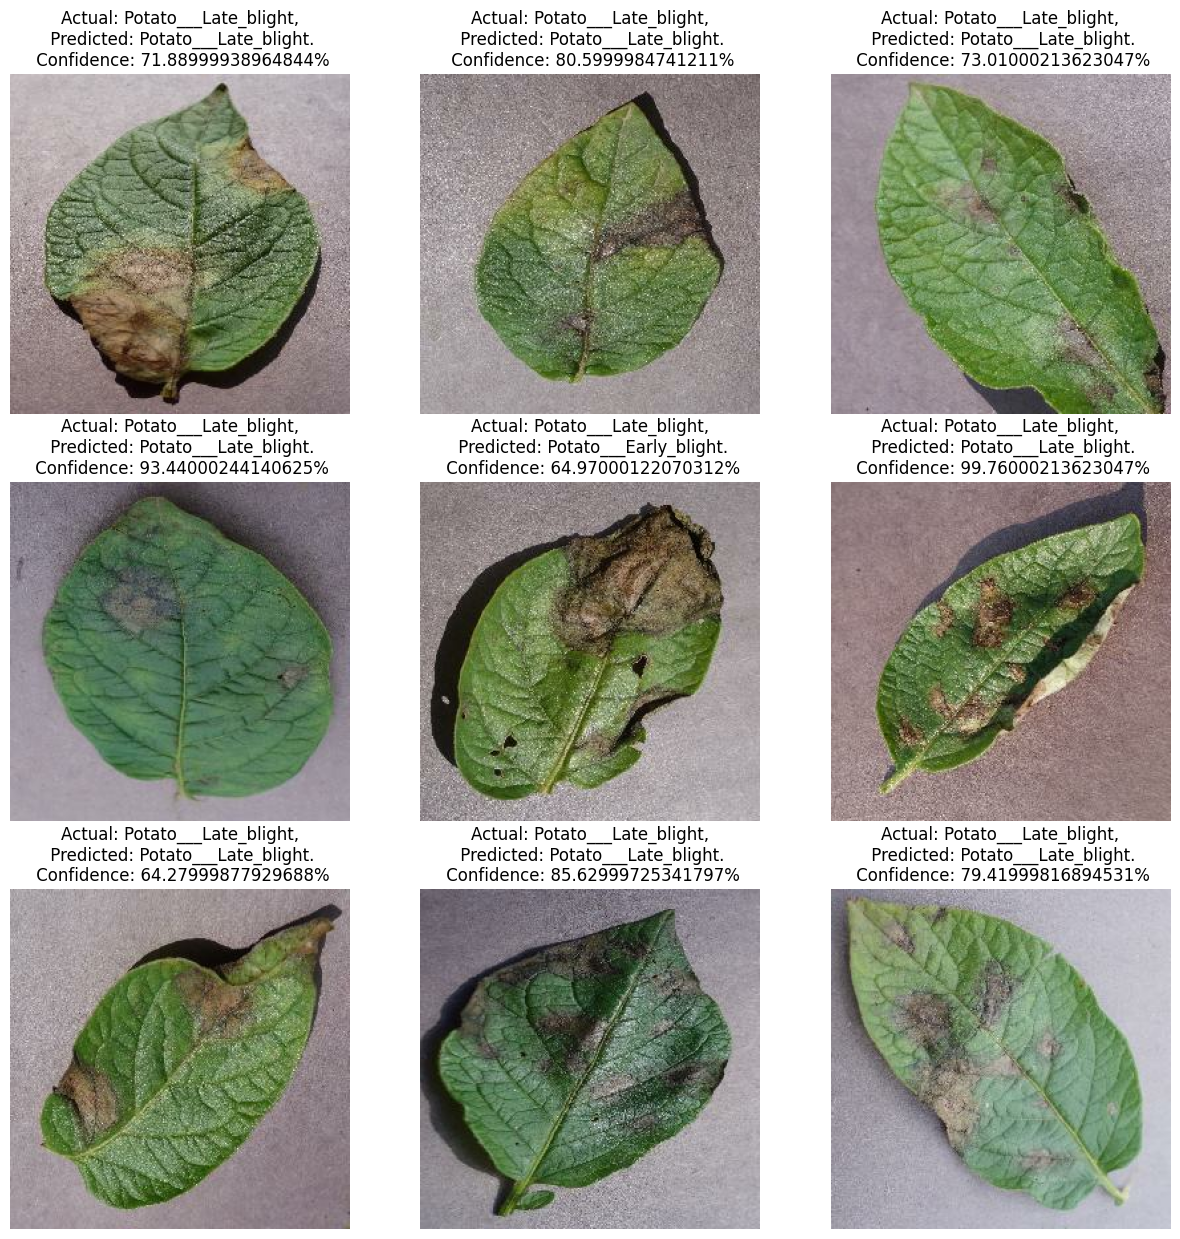

In [38]:
plt.figure(figsize=(15, 15))
for images, labels in test_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        
        predicted_class, confidence = predict(model, images[i].numpy())
        actual_class = class_names[labels[i]] 
        
        plt.title(f"Actual: {actual_class},\n Predicted: {predicted_class}.\n Confidence: {confidence}%")
        
        plt.axis("off")

In [ ]:
# import os
# model_version=max([int(i) for i in os.listdir("../models") + [0]])+1
# model.save(f"../models/{model_version}")

FileNotFoundError: [WinError 3] The system cannot find the path specified: '../models'

In [40]:
model.save("../potatoes.h5")